# Tutorial 1: The Poisson equation in 1D

This tutorial introduces the building blocks of `seemps_galerkin` on the simplest problem,

$$
-u''(x) = f(x), \quad x\in[0,1], \qquad u(0)=0, \quad u(1)=-1,
$$

with $f(x)=(3\pi/2)^2\sin(3\pi x/2)$, whose exact solution is $u(x)=\sin(3\pi x/2)$. We solve it
twice: with a dense Chebyshev–Galerkin discretization, and with the quantized tensor-train (QTT)
version, which is what makes large problems tractable.

## The problem class

The package solves elliptic systems for a field $u$ with $m$ components in $d$ coordinates,

$$
-\partial_\alpha\big(C_{\mu\alpha\nu\beta}\,\partial_\beta u_\nu\big) + R_{\mu\nu}\,u_\nu = f_\mu,
$$

with, on each face of the box, either a **Dirichlet** condition $u_\mu = g_\mu$ or a **Robin**
condition $(C\nabla u)_\mu\cdot n + S_{\mu\nu}u_\nu = g_\mu$, where $n$ is the outward normal
(a Neumann condition is a Robin condition with $S=0$). A problem is described by:

| Object | Content |
|---|---|
| `Mesh` (from SeeMPS) | the box, as one `ChebyshevInterval` per coordinate |
| `TensorField` | a tensor of fields on the mesh; empty entries (`None`) are zero |
| `BulkProblem(mesh, principal, reaction, source)` | $C$ with shape `(d, d, m, m)`, $R$ with shape `(m, m)`, $f$ with shape `(m,)` |
| `DirichletBoundaryCondition(face, data)` | $g$ with shape `(m,)` |
| `RobinBoundaryCondition(face, reaction, data)` | $S$ with shape `(m, m)` and $g$ with shape `(m,)` |
| `BoundaryProblem(mesh, conditions)` | one condition for each of the $2d$ faces |

All fields are given by their **values on the Chebyshev–Gauss nodes** of the mesh. For the Poisson
equation, $d=m=1$, $C=1$, $R=0$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seemps.analysis.mesh import ChebyshevInterval, Mesh
from seemps.state import MPS

from seemps_galerkin import (
    BoundaryFace,
    BoundaryProblem,
    BulkProblem,
    DirichletBoundaryCondition,
    TensorField,
)
from seemps_galerkin.dense.factories import vec_nd_chebyshev_transform
from seemps_galerkin.mps.factories import mps_identity
from seemps_galerkin.mps.factories.transform import mps_chebyshev_transform
from seemps_galerkin.solve import solve_dense_bvp, solve_mps_bvp


def exact(x):
    return np.sin(1.5 * np.pi * x)


def source(x):
    return (1.5 * np.pi) ** 2 * np.sin(1.5 * np.pi * x)

## 1. Mesh

A `ChebyshevInterval(a, b, N, endpoints=False)` holds the $N$ Chebyshev–Gauss nodes on $[a,b]$. The
physical interval is taken into account by the solver, so there is no need to map to $[-1,1]$.
For the QTT solver, $N$ must be a power of two, $N=2^n$, and each coordinate is then stored in $n$
binary sites.

In [2]:
n = 5
N = 2**n
mesh = Mesh([ChebyshevInterval(0.0, 1.0, N, endpoints=False)])
x = mesh.intervals[0].to_vector()
print(mesh.dimensions, x[:3])

(32,) [0.00060227 0.00541175 0.01498437]


## 2. Dense solve

With dense fields, each entry of a `TensorField` is a NumPy vector of nodal values. The boundary of
a 1D domain is a point, so the boundary data have an empty mesh shape `()` and a single value.
The solver returns the **Chebyshev coefficients** of the solution, which the inverse Chebyshev
transform turns back into nodal values.

In [3]:
principal = TensorField[np.ndarray]((1, 1, 1, 1), mesh.dimensions)
principal[0, 0, 0, 0] = np.ones(N)
reaction = TensorField[np.ndarray]((1, 1), mesh.dimensions)  # empty: R = 0
f = TensorField[np.ndarray]((1,), mesh.dimensions)
f[0] = source(x)
bulk = BulkProblem(mesh, principal, reaction, f)

left = TensorField[np.ndarray]((1,), ())
left[0] = np.array([0.0])
right = TensorField[np.ndarray]((1,), ())
right[0] = np.array([-1.0])
boundary = BoundaryProblem(
    mesh,
    [
        DirichletBoundaryCondition(BoundaryFace(dim=0, is_left=True), left),
        DirichletBoundaryCondition(BoundaryFace(dim=0, is_left=False), right),
    ],
)

coefficients = solve_dense_bvp(bulk, boundary)
u_dense = vec_nd_chebyshev_transform(coefficients, mesh.dimensions, inverse=True)
print(f"max error (dense): {np.max(np.abs(u_dense - exact(x))):.1e}")

max error (dense): 6.7e-16


## 3. QTT solve

The QTT version takes the same problem with every field given as an MPS over the $n$ binary
sites. Here the fields are small, so we build them from their nodal values with
`MPS.from_vector`; constant fields are multiples of `mps_identity(n)`, the all-ones MPS. The next
tutorial shows how to build fields from functions without ever forming the grid. A point (the
boundary of a 1D domain) is an MPS with a single site of dimension 1.

In [4]:
def point(value):
    return MPS([np.full((1, 1, 1), value)])


principal = TensorField[MPS]((1, 1, 1, 1), mesh.dimensions)
principal[0, 0, 0, 0] = mps_identity(n)
reaction = TensorField[MPS]((1, 1), mesh.dimensions)
f = TensorField[MPS]((1,), mesh.dimensions)
f[0] = MPS.from_vector(source(x), [2] * n, normalize=False)
bulk = BulkProblem(mesh, principal, reaction, f)

left = TensorField[MPS]((1,), ())
left[0] = point(0.0)
right = TensorField[MPS]((1,), ())
right[0] = point(-1.0)
boundary = BoundaryProblem(
    mesh,
    [
        DirichletBoundaryCondition(BoundaryFace(0, True), left),
        DirichletBoundaryCondition(BoundaryFace(0, False), right),
    ],
)

ψ = solve_mps_bvp(bulk, boundary)
u_qtt = mps_chebyshev_transform(ψ, [n], inverse=True).to_vector()
print(f"max error (QTT): {np.max(np.abs(u_qtt - exact(x))):.1e}, bond dimension {ψ.max_bond_dimension()}")

max error (QTT): 2.4e-09, bond dimension 3


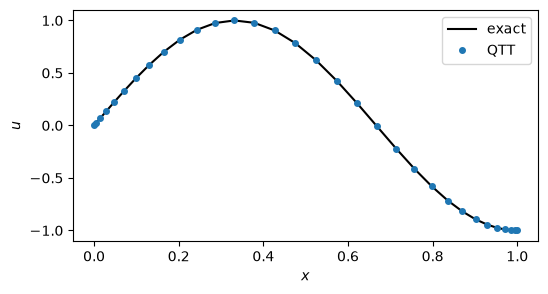

In [5]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(x, exact(x), "k-", label="exact")
ax.plot(x, u_qtt, "o", ms=4, label="QTT")
ax.set_xlabel("$x$")
ax.set_ylabel("$u$")
ax.legend()
plt.show()

## 4. Spectral convergence

For smooth solutions, the error decreases exponentially with $N$ until it reaches the accuracy of
the QTT solver (here, its default tolerance of about $10^{-9}$; Tutorial 3 shows how to change it).

In [6]:
for n in range(2, 7):
    N = 2**n
    mesh = Mesh([ChebyshevInterval(0.0, 1.0, N, endpoints=False)])
    x = mesh.intervals[0].to_vector()
    principal = TensorField[MPS]((1, 1, 1, 1), mesh.dimensions)
    principal[0, 0, 0, 0] = mps_identity(n)
    f = TensorField[MPS]((1,), mesh.dimensions)
    f[0] = MPS.from_vector(source(x), [2] * n, normalize=False)
    bulk = BulkProblem(mesh, principal, TensorField[MPS]((1, 1), mesh.dimensions), f)
    boundary = BoundaryProblem(
        mesh,
        [
            DirichletBoundaryCondition(BoundaryFace(0, True), left),
            DirichletBoundaryCondition(BoundaryFace(0, False), right),
        ],
    )
    ψ = solve_mps_bvp(bulk, boundary)
    error = np.max(np.abs(mps_chebyshev_transform(ψ, [n], inverse=True).to_vector() - exact(x)))
    print(f"N = {N:3d}: max error {error:.1e}")

N =   4: max error 7.6e-02
N =   8: max error 8.1e-05
N =  16: max error 2.3e-11
N =  32: max error 2.4e-09
N =  64: max error 6.7e-09


## Summary

- A problem is a `BulkProblem` (coefficients and source) and a `BoundaryProblem` (one condition per
  face), with all fields given by their values on the Chebyshev–Gauss nodes.
- `solve_dense_bvp` and `solve_mps_bvp` take the same problem with NumPy or MPS fields and return
  the Chebyshev coefficients of the solution.
- The inverse Chebyshev transform (`vec_nd_chebyshev_transform` or `mps_chebyshev_transform`) gives
  the solution back on the nodes.